# Memory Engine benchmark

This notebook is the evidence for the claim that the memory engine is useful to an agent. Every number below is
recomputed here from the stored run records in `benchmark/runs/`. No model is called and no service is touched,
so *Run All* takes seconds.

**What was measured.** LoCoMo [Maharana et al., ACL 2024] has ten long two-person conversations (272 sessions)
and 1,540 scored questions about them. Each conversation is retained into the engine as its own memory bank.
Each question is then answered by the same reader model under six conditions that differ only in what the reader is shown:

| condition | what the reader sees |
|---|---|
| `enhanced` | the full engine: extracted assertions with source quotes, inferences, graph, temporal planning |
| `raw_hybrid` | the engine's lexical + vector search over raw source chunks (plain RAG) |
| `recent_window` | the newest 8,192 tokens of the conversation, the same budget as the engine: what an agent without memory keeps |
| `full_context` | the whole conversation (an upper reference, and the most expensive) |
| `no_memory` | the question only |
| `no_graph`, `no_consolidation` | `enhanced` without one module (300-question stratified sample) |

Two judges from different model families grade every answer with Mem0's LoCoMo rubric: TypeSafe **Jev**, a decision
model (primary), and **gpt-4o-mini**, the judge Mem0 used. Mem0's token F1 and BLEU-1 need no model at all.
A separate deterministic property suite checks knowledge updates, relative dates, abstention, attribution and
credential filtering on the engine's stored state.

**How to check it.** `benchmark/README.md` shows how to re-run any stage. `run.py verify` rebuilds every stored prompt from
the stored retrieval and the pinned dataset, and `verify --live N` re-asks the models on N random items. The
spot-check section below prints random items in full so a reader can grade them by hand.

In [1]:
from pathlib import Path
import json, hashlib, random, collections, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option('display.max_colwidth', 120)
BENCH = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'benchmark/run.py').exists()) / 'benchmark'
RUN = BENCH / 'runs' / 'locomo-final'
PROPS = BENCH / 'runs' / 'properties-final'
CONFIG = json.loads((BENCH / 'config.json').read_text())
def read(p): return json.loads(Path(p).read_text())
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
report = read(RUN / 'report.json')
manifest = read(RUN / 'manifest.json')
items = pd.DataFrame([json.loads(l) for l in (RUN / 'items.jsonl').read_text().splitlines()])
ORDER = [c for c in CONFIG['conditions'] if c in report['conditions']]

## 1. Provenance

The run manifest freezes the code fingerprint, configuration, dataset checksum, model digests and hardware. The checks below recompute the checksums from the files on disk.

In [2]:
data = BENCH / 'data' / CONFIG['dataset']['file']
vendor = read(BENCH / 'vendor/mem0/manifest.json')
checks = {
    'dataset sha256 matches the pin': data.exists() and sha(data) == CONFIG['dataset']['sha256'],
    'dataset pin matches the run manifest': manifest['dataset_sha256'] == CONFIG['dataset']['sha256'],
    'source archive matches the manifest': sha(RUN / 'source.tar.gz') == manifest['source_archive_sha256'],
    **{f'vendored mem0/{f} matches upstream pin': sha(BENCH / 'vendor/mem0' / f) == e['sha256'] for f, e in vendor['files'].items()},
}
display(pd.DataFrame({'check': list(checks), 'passed': list(checks.values())}))
display(pd.DataFrame([{
    'run': RUN.name, 'split': manifest['split'], 'created': manifest['created_at'], 'commit': manifest['commit'],
    'code_fingerprint': manifest['code_fingerprint'][:16], 'worker': manifest['service']['worker_model'],
    'worker digest': (manifest.get('ollama_digests', {}).get(CONFIG['engine']['worker_model']) or '')[:16],
    'embedder': manifest['service']['embedding_model'], 'reader': f"{CONFIG['reader']['provider']}/{CONFIG['reader']['model']}",
    'gpu': manifest['hardware']['gpu'], 'items': len(manifest['item_ids'])}]).T.rename(columns={0: 'value'}))

,check,passed
0,dataset sha256 matches the pin,True
1,dataset pin matches the run manifest,True
2,source archive matches the manifest,True
3,vendored mem0/llm_judge.py matches upstream pin,True
4,vendored mem0/prompts.py matches upstream pin,True
5,vendored mem0/utils.py matches upstream pin,True


,value
run,locomo-final
split,test
created,2026-10-21T08:01:01.055427+00:00
commit,c08dc7f998d0a76459b6bf6325c261cbf832f0e9
code_fingerprint,fec4ed16c0166dad
worker,ollama/mem-extractor:general-v2
worker digest,b7b1efbb7e0e4084
embedder,qwen3-embedding:0.6b
reader,claude-bridge/claude-haiku-5-5
gpu,"NVIDIA GeForce RTX 4070 Laptop GPU, 8188 MiB, 595.91.07"


## 2. Dataset

In [3]:
import sys; sys.path.insert(0, str(BENCH))
import run as bench
banks, all_items = bench.load()
sessions = [s for b in banks.values() for s in b['sessions']]
turns = [t for s in sessions for t in s['turns']]
display(pd.DataFrame([{'conversations': len(banks), 'sessions': len(sessions), 'turns': len(turns),
                       'characters': sum(len(t['content']) for t in turns),
                       'scored questions': len(all_items)}]))
display(pd.Series(collections.Counter(i['category'] for i in all_items), name='questions').to_frame())

,conversations,sessions,turns,characters,scored questions
0,10,272,5882,858994,1540


,questions
temporal,321
open_domain,96
multi_hop,282
single_hop,841


## 3. Pre-registered success criteria

These thresholds were committed to `benchmark/config.json` before the test run; `git log -p benchmark/config.json`
shows the order. They are evaluated on the primary judge.

In [4]:
display(pd.Series({k: v for k, v in CONFIG['criteria'].items() if k != 'note'}, name='threshold').to_frame())
display(pd.Series(report['criteria'], name='result').to_frame())

,threshold
beats_no_memory_by,0.3
beats_recent_window,True
not_below_raw_hybrid,True
within_full_context_by,0.1
max_token_share_of_full_context,0.5
quote_exactness,1.0


,result
above_raw_hybrid,True
beats_no_memory,True
beats_recent_window,True
not_below_raw_hybrid,True
quotes_exact,True
token_share_of_full_context,0.303134
token_share_ok,True
within_full_context,True


## 4. Main results

In [5]:
rows = []
for c in ORDER:
    s = report['conditions'][c]
    rows.append({'condition': c, 'n': s['answered'], 'Jev accuracy': s.get('jev_accuracy'),
                 'gpt-4o-mini accuracy': s.get('gpt4omini_accuracy'), 'F1': s['f1'], 'BLEU-1': s['bleu1'],
                 'context tokens (mean)': s['context_tokens_mean'],
                 'recall p50 ms': s.get('recall_ms_p50'), 'recall p95 ms': s.get('recall_ms_p95'),
                 'reader p50 s': s['reader_seconds_p50']})
main = pd.DataFrame(rows).set_index('condition')
display(main.style.format(precision=3, na_rep='–'))

,n,Jev accuracy,gpt-4o-mini accuracy,F1,BLEU-1,context tokens (mean),recall p50 ms,recall p95 ms,reader p50 s
condition,,,,,,,,,
enhanced,1540,0.831,0.832,0.558,0.484,6790.121,428.000,584.000,5.217
raw_hybrid,1540,0.800,0.801,0.535,0.464,4472.753,420.000,569.000,5.459
recent_window,1540,0.430,0.423,0.289,0.250,8168.292,–,–,5.176
full_context,1540,0.890,0.888,0.604,0.526,22399.745,–,–,5.462
no_memory,1540,0.003,0.004,0.005,0.020,7.000,–,–,4.098
assertions_only,300,0.667,0.667,0.413,0.357,5565.680,422.000,541.000,5.239
no_graph,300,0.763,0.767,0.479,0.416,6605.887,425.000,550.000,5.300
no_consolidation,300,0.747,0.757,0.473,0.405,6634.877,424.000,555.000,5.125


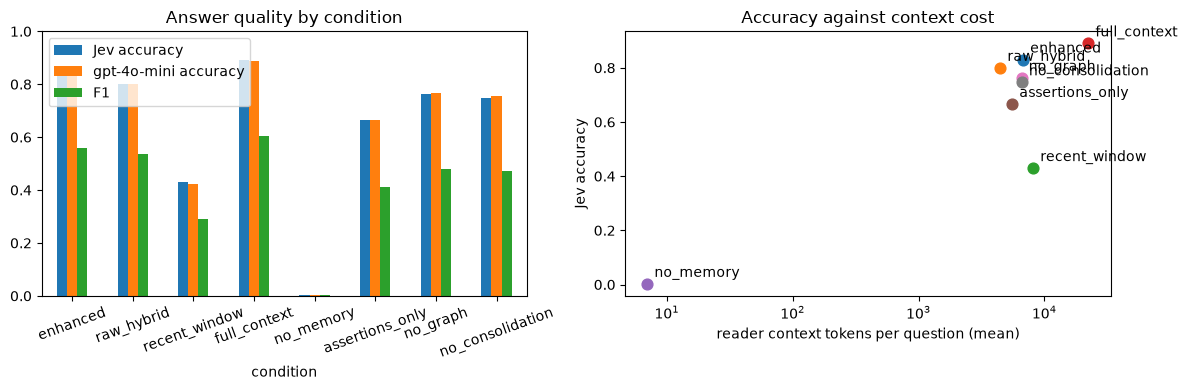

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
main[['Jev accuracy', 'gpt-4o-mini accuracy', 'F1']].plot.bar(ax=axes[0], rot=20)
axes[0].set_ylim(0, 1); axes[0].set_title('Answer quality by condition'); axes[0].legend(loc='upper left')
for c in ORDER:
    axes[1].scatter(main.loc[c, 'context tokens (mean)'], main.loc[c, 'Jev accuracy'], s=60)
    axes[1].annotate(c, (main.loc[c, 'context tokens (mean)'], main.loc[c, 'Jev accuracy']), xytext=(5, 5), textcoords='offset points')
axes[1].set_xscale('symlog'); axes[1].set_xlabel('reader context tokens per question (mean)'); axes[1].set_ylabel('Jev accuracy')
axes[1].set_title('Accuracy against context cost'); plt.tight_layout(); plt.show()

## 5. Paired differences against `enhanced`

Paired bootstrap (2,000 resamples) over the same questions; positive means `enhanced` is better.

In [7]:
rows = []
for judge, table in report['paired_vs_enhanced'].items():
    for c, ci in table.items():
        if ci: rows.append({'judge': judge, 'baseline': c, 'n': ci['n'], 'enhanced minus baseline': ci['difference'],
                            'per-question ci95': f"[{ci['ci95'][0]:+.3f}, {ci['ci95'][1]:+.3f}]",
                            'per-conversation ci95': f"[{ci['cluster_ci95'][0]:+.3f}, {ci['cluster_ci95'][1]:+.3f}]"})
display(pd.DataFrame(rows).style.format(precision=3))

,judge,baseline,n,enhanced minus baseline,per-question ci95,per-conversation ci95
0,gpt4omini,assertions_only,300,0.093,"[+0.043, +0.140]","[+0.041, +0.165]"
1,gpt4omini,full_context,1540,-0.056,"[-0.075, -0.040]","[-0.072, -0.041]"
2,gpt4omini,no_consolidation,300,0.003,"[-0.027, +0.030]","[-0.018, +0.020]"
3,gpt4omini,no_graph,300,-0.007,"[-0.040, +0.027]","[-0.034, +0.016]"
4,gpt4omini,no_memory,1540,0.828,"[+0.808, +0.846]","[+0.805, +0.851]"
5,gpt4omini,raw_hybrid,1540,0.031,"[+0.012, +0.050]","[+0.014, +0.046]"
6,gpt4omini,recent_window,1540,0.408,"[+0.381, +0.435]","[+0.373, +0.442]"
7,jev,assertions_only,300,0.097,"[+0.047, +0.147]","[+0.041, +0.151]"
8,jev,full_context,1540,-0.060,"[-0.079, -0.043]","[-0.069, -0.050]"
9,jev,no_consolidation,300,0.017,"[-0.013, +0.043]","[+0.003, +0.033]"


### Held-out conversations

Faults were diagnosed on conv-26 and conv-30 only (see section 11). The same table for the other eight
conversations, which no fix ever looked at:

In [8]:
if 'held_out' in report:
    h = report['held_out']
    display(Markdown('Conversations: ' + ', '.join(h['conversations'])))
    display(pd.DataFrame([{'condition': c, 'n': h['conditions'][c]['answered'], 'Jev': h['conditions'][c].get('jev_accuracy'),
                           'gpt-4o-mini': h['conditions'][c].get('gpt4omini_accuracy'), 'F1': h['conditions'][c]['f1']}
                          for c in ORDER if c in h['conditions']]).set_index('condition').style.format(precision=3))
    display(pd.Series(h['criteria'], name='criteria on held-out').to_frame())

Conversations: conv-41, conv-42, conv-43, conv-44, conv-47, conv-48, conv-49, conv-50

,n,Jev,gpt-4o-mini,F1
condition,,,,
enhanced,1307,0.830,0.828,0.559
raw_hybrid,1307,0.794,0.790,0.536
recent_window,1307,0.415,0.406,0.278
full_context,1307,0.889,0.883,0.606
no_memory,1307,0.002,0.004,0.005
assertions_only,251,0.669,0.677,0.414
no_graph,251,0.749,0.753,0.469
no_consolidation,251,0.741,0.745,0.465


,criteria on held-out
above_raw_hybrid,True
beats_no_memory,True
beats_recent_window,True
not_below_raw_hybrid,True
quotes_exact,True
token_share_of_full_context,0.289585
token_share_ok,True
within_full_context,True


### Run-to-run noise

Repeats 1 and 2 re-ask the reader on the same 300-question sample. If the spread here is small next to the
differences above, those differences are not reader noise.

In [9]:
display(pd.DataFrame([{'condition': c, 'questions': v['questions'],
                       **{f'repeat {k}': a for k, a in enumerate(v['accuracy_by_repeat'])},
                       'stdev': v['accuracy_stdev'], 'verdict flip rate': v['verdict_flip_rate']}
                      for c, v in report['repeats'].items()]).set_index('condition').style.format(precision=3, na_rep='–'))

,questions,repeat 0,repeat 1,repeat 2,stdev,verdict flip rate
condition,,,,,,
enhanced,300,0.763,0.770,0.773,0.005,0.073
full_context,300,0.850,0.857,0.860,0.005,0.077
raw_hybrid,300,0.763,0.743,0.767,0.013,0.080
recent_window,300,0.473,0.477,0.463,0.007,0.067


## 6. By question category

condition,enhanced,raw_hybrid,recent_window,full_context,no_memory,assertions_only,no_graph,no_consolidation
category,,,,,,,,
multi_hop,0.830,0.745,0.514,0.887,0.004,0.787,0.773,0.800
open_domain,0.583,0.604,0.406,0.635,0.031,0.533,0.587,0.533
single_hop,0.870,0.839,0.449,0.933,0.000,0.733,0.893,0.880
temporal,0.801,0.804,0.312,0.857,0.000,0.613,0.800,0.773


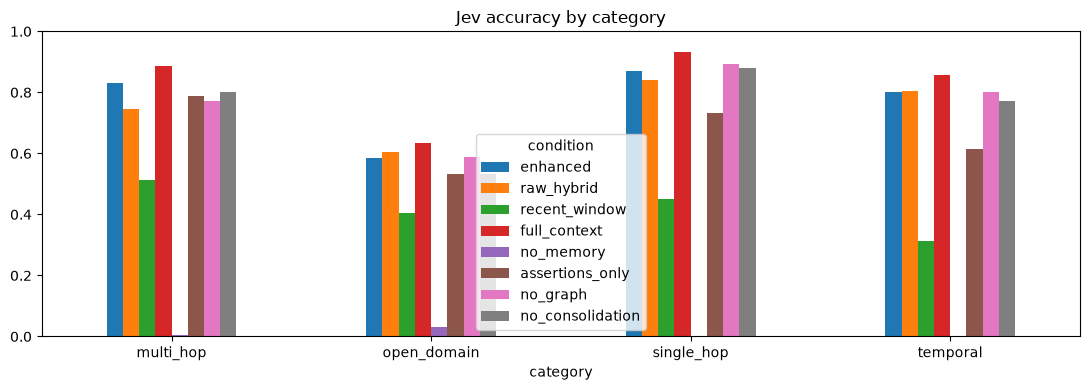

In [10]:
cat = pd.DataFrame([{'condition': c, 'category': k, 'n': v['n'], 'Jev': v.get('jev_accuracy'), 'gpt-4o-mini': v.get('gpt4omini_accuracy'), 'F1': v['f1']}
                    for c in ORDER for k, v in report['conditions'][c]['categories'].items()])
pivot = cat.pivot(index='category', columns='condition', values='Jev')[ORDER]
display(pivot.style.format(precision=3, na_rep='–'))
pivot.plot.bar(figsize=(11, 4), rot=0, title='Jev accuracy by category'); plt.ylim(0, 1); plt.tight_layout(); plt.show()

## 7. Retrieval quality and provenance

LoCoMo labels the dialogue turns that answer each question. Packed recall is the share of those evidence sessions and turns whose text reaches the reader. Every source quote returned with a recall result is checked against the original dataset turn it cites.

In [11]:
rows = []
for c in ORDER:
    s = report['conditions'][c]
    if 'retrieval' in s:
        rows.append({'condition': c, **s['retrieval'], 'quotes checked': s['quotes_checked'], 'quote exactness': s['quote_exactness']})
display(pd.DataFrame(rows).set_index('condition').style.format(precision=3))

,packed_session_recall,packed_turn_recall,session_recall@10,session_recall@20,session_recall@5,session_recall_all@10,session_recall_all@20,session_recall_all@5,quotes checked,quote exactness
condition,,,,,,,,,,
enhanced,0.969,0.844,0.884,0.959,0.799,0.835,0.935,0.743,99971,1.000
raw_hybrid,0.976,0.806,0.895,0.970,0.803,0.844,0.939,0.743,61803,1.000
assertions_only,0.934,0.622,0.747,0.889,0.511,0.661,0.836,0.416,20386,1.000
no_graph,0.954,0.807,0.864,0.945,0.757,0.789,0.913,0.661,19150,1.000
no_consolidation,0.951,0.788,0.820,0.936,0.719,0.738,0.903,0.617,19110,1.000


## 8. Judge agreement

The two judges never see the condition. Cohen’s kappa measures their agreement beyond chance.

In [12]:
if report['judge_agreement'] and {'jev', 'gpt4omini'} <= set(items.columns):
    display(pd.Series(report['judge_agreement'], name='value').to_frame())
    both = items.dropna(subset=['jev', 'gpt4omini'])
    display(pd.crosstab(both['jev'], both['gpt4omini'], rownames=['Jev'], colnames=['gpt-4o-mini']))
else:
    display(Markdown('Only one judge has graded this run.'))

,value
agreement,0.967442
kappa,0.931907
n,8600.000000


gpt-4o-mini,0,1
Jev,,
0,3261,138
1,142,5059


## 9. Cost of building memory

Ingestion runs once per conversation on the 8 GB laptop GPU; recall is per question.

In [13]:
ing = report['ingestion']
display(pd.DataFrame([{**{k: v for k, v in ing.items() if k != 'worker_ms'},
                       **{f'{k} (GPU-busy hours)': v / 3.6e6 for k, v in ing['worker_ms'].items()}}]).T.rename(columns={0: 'value'}))

,value
bank_seconds_sum,57173.108111
banks,10.000000
characters,858994.000000
permanently_failed_jobs,0.000000
sessions,272.000000
turns,5882.000000
worker_consolidate (GPU-busy hours),0.632014
worker_extract (GPU-busy hours),15.227515
worker_project (GPU-busy hours),0.007258


## 10. Deterministic property suite

Scripted conversations checked against the engine’s stored state and responses; no judge is involved. The reader comparison asks the same questions over three contexts and scores answers by string match.

In [14]:
if (PROPS / 'summary.json').exists():
    props = read(PROPS / 'summary.json')
    display(pd.DataFrame([{'check': k, **v, 'rate': v['passed'] / v['n']} for k, v in props['checks'].items()]).set_index('check').style.format({'rate': '{:.2f}'}))
    display(pd.DataFrame([{'family': f, 'condition': c, **v, 'rate': v['correct'] / v['n']}
                          for f, t in props['reader'].items() for c, v in t.items()]).pivot(index='family', columns='condition', values='rate'))
else:
    display(Markdown('**Property suite results are not available locally.**'))

,n,passed,rate
check,,,
abstention.abstains_without_evidence,6,6,1.00
abstention.answers_with_evidence,6,6,1.00
abstention.source_quotes_verbatim,6,6,1.00
attribution.own_city_not_superseded,6,6,1.00
attribution.own_city_still_active,6,2,0.33
attribution.relative_move_not_attributed_to_user,6,6,1.00
attribution.source_quotes_verbatim,6,6,1.00
credential.ordinary_fact_kept,4,2,0.50
credential.secret_never_stored,4,4,1.00


condition,enhanced,full_context,raw_hybrid
family,,,
attribution,1.0,1.0,1.0
knowledge_update,1.0,1.0,1.0
relative_date,1.0,1.0,1.0


## 11. Iterations on the dev split

`benchmark/iterations.json` records each change made after a dev run, why, and the dev numbers before and after. The test run used only the final version.

In [15]:
it = read(BENCH / 'iterations.json')
display(pd.DataFrame(it['iterations']).set_index('version'))

,date,dev_run,finding,change,files,dev_before,dev_after,decision
version,,,,,,,,
v1-window-split,2026-10-20,locomo-dev-v1,"Ingesting conv-30 failed: on one crowded session the extractor's answer hit the 3,072-token output cap (OLLAMA_NUM_P...",A window whose answer is cut off at the output cap is split in half and each half is extracted on its own; only a si...,"[src/lib.rs, src/model.rs, src/worker/extraction.rs, tests/assertion_graph.rs]",conv-30 bank could not be built,"The retried conv-30 job split a 26-event window (engine log, 10:43:30Z) and succeeded; the bank finished extracting.",NaN
v2-relative-days,2026-10-20,locomo-dev-v2,"In conv-26, 'I went to a LGBTQ support group yesterday' said on 8 May 2023 was stored with event_at 8 May and the st...","After review, a claim whose own quotes name exactly one relative day (yesterday, tomorrow, N days ago, in N days, la...","[src/temporal.rs, src/worker/extraction.rs]",pending (locomo-dev-v1 banks were incomplete),pending,NaN
v2-harness-session-ids,2026-10-20,locomo-dev-v1,"Harness bug: recall reports a source by its session name (session_19), but the harness labelled evidence as conv-26:...","Evidence sessions and the quote check use the session name, which is unique within one conversation's bank.","[benchmark/run.py, benchmark/test_protocol.py]",session recall 0 on every item,"conv-26:q0 session recall 1.0, 26/26 quotes verbatim",NaN
v3-consolidation-budget,2026-10-20,locomo-dev-v2,"Once a LoCoMo speaker had about a dozen sessions of assertions, every consolidation job for that speaker failed befo...",Consolidation keeps the newest assertions whose prompt fits the context with a repair reserve and no more than the 6...,"[src/worker/prompts.rs, src/worker/consolidation.rs, src/worker/mod.rs]",18 of 28 consolidations failed across the two dev banks,all 38 consolidations of the two dev banks succeed; on conv-26 one job kept the newest 38 of 81 assertions,NaN
v3-harness-engine-restarts,2026-10-20,locomo-dev-v2,Harness fault: restarting the engine while a bank was being built crashed the ingest stage (connection refused) inst...,"Every engine call in ingest, recall and the property suite retries for about 15 minutes before giving up.","[benchmark/run.py, benchmark/properties.py]",ingest stage exited on an engine restart,resumed ingest waits through restarts,NaN
v3-failed-job-visibility,2026-10-20,locomo-dev-v2,"Harness and API fault: /api/v2/jobs returns only the newest 100 jobs, and a LoCoMo bank makes hundreds of projection...","/api/v2/jobs accepts status=failed (and any other status). The harness decides readiness from the status endpoint, w...","[src/knowledge_store/jobs.rs, src/v2/mod.rs, benchmark/run.py, benchmark/test_protocol.py]",conv-26 reported ready with 12 failed consolidations,"the 12 were found, retried on the v3 engine and succeeded; both dev banks have all 19 extractions and 19 consolidations",NaN
v4-stated-changes-and-miscounted-days,2026-10-20,properties-dev-v3,"Property suite on the v3 engine: in 4 of 12 knowledge updates ('Big news: I moved from Hobart to Accra last weekend,...","A correction is not vetoed when its own quote states the change in words (moved from, switched to, no longer, sold m...","[src/worker/review.rs, src/worker/extraction.rs]",knowledge_update old value superseded 8/12; relative_date resolved 8/12 (3 of the 4 misses were events never extracted),pending,NaN
v5-hybrid-recall,2026-10-20,locomo-dev-v2,"On the two dev conversations, assertions alone (the v1 'enhanced' design) answered 0.459 (Jev) against 0.798 for pla...","Recall with source text packs source chunks and assertions alternately, each in its own ranked order (packing_order)...","[src/v2/recall.rs, benchmark/config.json]","assertions only 0.459; mixed by fused rank 0.768 (top_k 20), 0.807 (top_k 60); plain retrieval 0.824 (top_k 60)","hybrid 0.828 at top_k 60 (multi-hop 0.77 vs 0.67, open-domain 0.85 vs 0.77 for plain retrieval; 7,046 context tokens...",NaN
v6-extractor-coverag

## 12. Spot check

Ten random questions, shown in full, so a reader can grade them by hand. Re-run the cell for another sample.

In [16]:
rng = random.Random()
for qid in rng.sample(sorted(items['id'].unique()), 10):
    rows = items[items['id'] == qid]
    first = rows.iloc[0]
    display(Markdown(f"**{qid}** ({first['category']}) · *{first['question']}* · gold: **{first['answer']}**"))
    display(rows[[c for c in ['condition', 'hypothesis', 'jev', 'gpt4omini', 'f1'] if c in rows]].set_index('condition'))
    recall = RUN / 'recall' / 'enhanced' / f'{qid}.json'
    if recall.exists():
        print(read(recall)['context'][:1500], '\n...')

**conv-41:q17** (open_domain) · *What might John's degree be in?* · gold: **Political science, Public administration, Public affairs**

,hypothesis,jev,gpt4omini,f1
condition,,,,
enhanced,Likely political science or public policy,1,1,0.545455
raw_hybrid,Likely political science/public policy,1,1,0.222222
recent_window,Mechanical engineering,0,0,0.000000
full_context,Probably mechanical engineering,0,0,0.000000
no_memory,Unknown; no memories available,0,0,0.000000
assertions_only,Political science or public policy,1,1,0.600000
no_graph,Likely political science (policy-related),1,1,0.444444
no_consolidation,Not stated; likely policy-related,1,0,0.000000


[35f184fe-32b4-4b77-a06b-adba54771bca] John: Hey Maria! Awesome to hear from you. Sounds like a great way to delve into your feelings. Since we spoke last, I've had quite the adventure!
 [shares a photo: a photo of a certificate of completion of a university degree] [source_chunk; raw; valid_from=None; valid_to=None; event_at=None]
  Source (session_9, user, 2023-04-02 09:36:00 UTC): John: Hey Maria! Awesome to hear from you. Sounds like a great way to delve into your feelings. Since we spoke last, I've had quite the adventure!
 [shares a photo: a photo of a certificate of completion of a university degree]
[11b4ae90-0aef-4902-b5fe-63a54b78fa20] John thinks the variety of yoga and fitness classes at his studio keeps things interesting. [preference; active; valid_from=Some(2023-07-22T18:21:00Z); valid_to=None; event_at=None]
  Source (session_25, user, 2023-07-22 18:21:00 UTC): It keeps things interesting!
[bdf6ffb1-2125-432c-985a-e2e1e566537a] Maria: Congrats on finishing your degree, 

**conv-43:q136** (single_hop) · *What did Tim say about his injury on 16 November, 2023?* · gold: **The doctor said it's not too serious**

,hypothesis,jev,gpt4omini,f1
condition,,,,
enhanced,Hoped John's injury would heal soon.,0,0,0.000000
raw_hybrid,Hoped the injury would heal soon,0,0,0.153846
recent_window,Tim mentioned no injury,0,0,0.000000
full_context,"Ouch, bummer about the injury",0,0,0.166667
no_memory,No memories available to answer,0,0,0.000000


...

,hypothesis,jev,gpt4omini,f1
condition,,,,
enhanced,September 2023,1,1,1.0
raw_hybrid,September 2023,1,1,1.0
recent_window,Not mentioned in memories,0,0,0.0
full_context,September 2023,1,1,1.0
no_memory,Unknown; no memories provided,0,0,0.0
assertions_only,September 2023,1,1,1.0
no_graph,September 2023,1,1,1.0
no_consolidation,September 2023,1,1,1.0


[e04e4b13-bf67-458a-b39e-5cc3ead5c0aa] Tim: I have no big events coming up, but I'm hoping to attend a book conference next month. It's an interesting gathering of authors, publishers and book lovers where we talk about our favorite novels and new releases. I'm excited to go because it'll help me learn more about literature and create a stronger bond to it. [source_chunk; raw; valid_from=None; valid_to=None; event_at=None]
  Source (session_7, user, 2023-08-17 19:54:00 UTC): Tim: I have no big events coming up, but I'm hoping to attend a book conference next month. It's an interesting gathering of authors, publishers and book lovers where we talk about our favorite novels and new releases. I'm excited to go because it'll help me learn more about literature and create a stronger bond to it.
[949b6b06-b16c-452b-b442-419743282495] Tim plans to attend a book conference in September 2023, which he hopes will help him learn more about literature and create a stronger connection to the subjec

**conv-48:q8** (multi_hop) · *What helped Deborah find peace when grieving deaths of her loved ones?* · gold: **yoga, old photos, the roses and dahlias in a flower garden, nature**

,hypothesis,jev,gpt4omini,f1
condition,,,,
enhanced,"Art, nature, and yoga",1,1,0.375000
raw_hybrid,"Artwork, nature, and family photos",1,1,0.352941
recent_window,"Yoga, nature, and self-reflection",1,1,0.375000
full_context,"Yoga, nature, and her mom's bench",1,1,0.333333
no_memory,Not stated in memories,0,0,0.125000
assertions_only,Nature and yoga practice,1,1,0.375000
no_graph,Artwork keeping memories alive,0,0,0.000000
no_consolidation,Artwork and nature,1,1,0.266667


[e556f19b-3b21-47a7-8b5f-adf5d969bbde] Deborah: Finding ways to keep her memory alive gives me peace. It's amazing how something simple like artwork can bring back powerful emotions and remind us of those we've lost. It's about finding solace in the things we love, and art has done that for me. [source_chunk; raw; valid_from=None; valid_to=None; event_at=None]
  Source (session_12, user, 2023-04-09 16:30:00 UTC): Deborah: Finding ways to keep her memory alive gives me peace. It's amazing how something simple like artwork can bring back powerful emotions and remind us of those we've lost. It's about finding solace in the things we love, and art has done that for me.
[0e05f095-5a5d-412e-a208-6b0088debad2] As of 2023-08-21, Deborah has been doing yoga for three years and finds it helpful to escape studying and work stress. [profile; active; valid_from=Some(2023-08-21T09:11:00Z); valid_to=None; event_at=None]
  Source (session_20, user, 2023-08-21 09:11:00 UTC): It's so calming and helps m

## 13. Comparison with published systems

Published LoCoMo results from the Mem0 paper (Chhikara et al., 2025, Tables 1 and 2), checked against the paper and
stored in `benchmark/published.json`. They answer with GPT-4o-mini and this benchmark answers with Claude Haiku 5.5,
so absolute scores are not comparable. The fair comparison is each system's distance from its own full-context
baseline and the context it needs.

In [17]:
pub = read(BENCH / 'published.json')
ours = report['conditions']
rows = [{'system': f'{k} (published)', 'judge accuracy': v, 'gap to own full context': v - pub['locomo_overall_j']['Full-context'],
         'context tokens': pub['locomo_context_tokens'].get(k.split(' (')[0])}
        for k, v in pub['locomo_overall_j'].items()]
fc = ours['full_context']['gpt4omini_accuracy'] if ours['full_context'].get('gpt4omini_accuracy') is not None else ours['full_context']['jev_accuracy']
for c in ('full_context', 'enhanced', 'raw_hybrid', 'recent_window'):
    if c in ours:
        a = ours[c].get('gpt4omini_accuracy') if ours[c].get('gpt4omini_accuracy') is not None else ours[c]['jev_accuracy']
        rows.append({'system': f'this engine: {c}', 'judge accuracy': 100 * a, 'gap to own full context': 100 * (a - fc),
                     'context tokens': ours[c]['context_tokens_mean']})
display(Markdown(pub['caveat']))
display(pd.DataFrame(rows).set_index('system').style.format(precision=1, na_rep='–'))

Published numbers use GPT-4o-mini to answer. Their judge is gpt-4o-mini in Mem0's released evaluation code (vendored in vendor/mem0/llm_judge.py). This benchmark answers with Claude Haiku 5.5, so absolute scores are not directly comparable; compare the gap to each paper's own full-context baseline.

,judge accuracy,gap to own full context,context tokens
system,,,
Full-context (published),72.9,0.0,26031.0
Mem0g (published),68.4,-4.5,3616.0
Mem0 (published),66.9,-6.0,1764.0
Zep (published),66.0,-6.9,3911.0
"RAG (best, k=2, 256-token chunks) (published)",61.0,-11.9,–
LangMem (published),58.1,-14.8,127.0
OpenAI (published),52.9,-20.0,4437.0
A-Mem (published),48.4,-24.5,2520.0
this engine: full_context,88.8,0.0,22399.7


## 14. Verification

In [18]:
v = RUN / 'verification.json'
display(pd.Series({k: (len(x) if isinstance(x, list) else x) for k, x in read(v).items() if k != 'live'}, name='value').to_frame() if v.exists()
        else Markdown('Run `python3 benchmark/run.py verify --split test` to produce verification.json.'))
if v.exists() and 'live' in read(v):
    display(pd.DataFrame(read(v)['live']).T)

,value
answers_checked,11000
judgments_checked,22000
problems,0
